# 05 · Baseline correction

`s.baseline(method, **settings)` subtracts the baseline; `stk.find_baseline(s, method)` gives the baseline itself.

| method | idea | main setting |
|---|---|---|
| `airpls` (default) | smooth curve, ignores points on bands, adapts weights | `lam` (stiffness) |
| `asls` | your baseline.m | `lam`, `p` |
| `arpls`, `iasls` | improved AsLS | `lam` |
| `modpoly`, `imodpoly` | polynomial clipped under the bands | `order` |
| `rollingball`, `snip` | window wider than the bands | `window` (cm⁻¹) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import spectrum_toolkit as stk
from spectrum_toolkit.baseline import METHODS, DEFAULTS

cv = stk.load('../data/CV10-4M.xlsx', verbose=False).despike(verbose=False)   # remove spikes first
s = cv[0]
DEFAULTS

{'asls': {'lam': 100000.0, 'p': 0.005, 'max_iter': 10, 'tol': 0.0},
 'iasls': {'lam': 10000.0,
  'p': 0.005,
  'lam1': 0.0001,
  'max_iter': 30,
  'tol': 0.001},
 'arpls': {'lam': 1000000.0, 'max_iter': 50, 'tol': 0.001},
 'airpls': {'lam': 1000000.0, 'max_iter': 50, 'tol': 0.001},
 'modpoly': {'order': 5, 'max_iter': 250, 'tol': 0.001},
 'imodpoly': {'order': 5, 'max_iter': 250, 'tol': 0.001, 'num_std': 1.0},
 'rollingball': {'window': 100.0, 'smooth': None},
 'snip': {'window': 100.0, 'decreasing': True}}

## 1. All methods on one CV spectrum

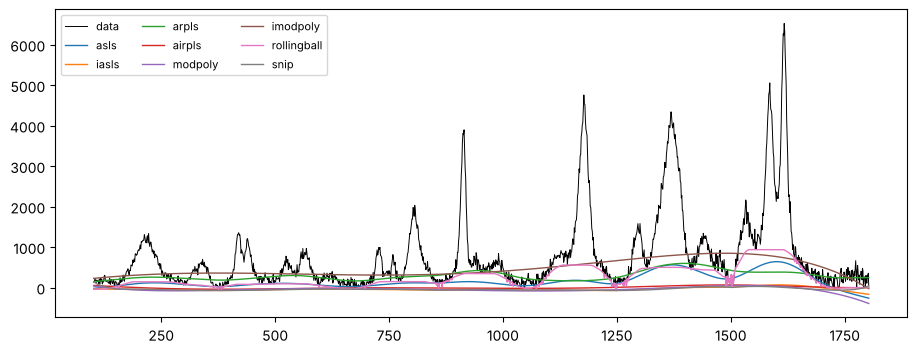

In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(s.x, s.y, 'k', lw=0.7, label='data')
for m in METHODS:
    ax.plot(s.x, stk.find_baseline(s, m).y, lw=1, label=m)
ax.legend(ncol=3, fontsize=8); plt.show()

## 2. Before and after

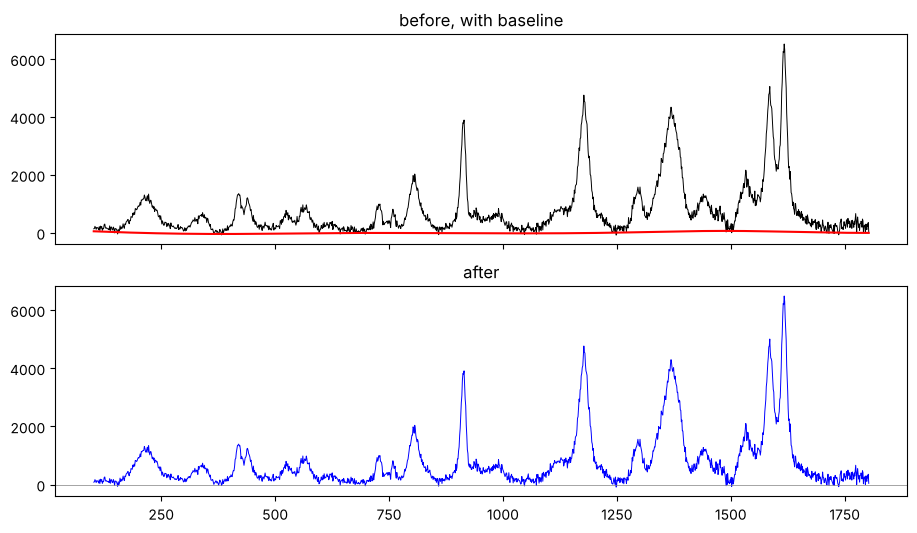

({'step': 'despike',
  'method': 'single',
  'threshold': 8.0,
  'width': 3,
  'sharpness': 1.0,
  'grow': 3.0,
  'passes': 2,
  'spikes': {'Spectrum 4': [{'x_from': 1634.62695,
     'x_to': 1636.79688,
     'points': 3,
     'change': -2725.3405570183495},
    {'x_from': 1696.18359,
     'x_to': 1701.55664,
     'points': 6,
     'change': -9027.529511807266}],
   'Spectrum 11': [{'x_from': 313.29883,
     'x_to': 314.61133,
     'points': 2,
     'change': -1849.3796585175437}]}},
 {'step': 'baseline',
  'method': 'airpls',
  'lam': 1000000.0,
  'max_iter': 50,
  'tol': 0.001})

In [3]:
after = s.baseline()            # airpls, lam 1e6
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(s.x, s.y, 'k', lw=0.7); ax[0].plot(s.x, stk.find_baseline(s).y, 'r'); ax[0].set_title('before, with baseline')
ax[1].plot(after.x, after.y, 'b', lw=0.7); ax[1].axhline(0, color='0.5', lw=0.5); ax[1].set_title('after')
plt.show()
after.history

## 3. Play with the settings

Move the sliders; only the settings that belong to the chosen method are used.

In [4]:
from ipywidgets import interact, Dropdown, FloatLogSlider, IntSlider, FloatSlider

def show(method='airpls', lam=1e6, p=0.005, order=5, window=100.0):
    settings = {k: v for k, v in dict(lam=lam, p=p, order=order, window=window).items() if k in DEFAULTS[method]}
    z = stk.find_baseline(s, method, **settings)
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    ax[0].plot(s.x, s.y, 'k', lw=0.7); ax[0].plot(z.x, z.y, 'r'); ax[0].set_title(f'{method} {settings}')
    ax[1].plot(s.x, s.y - z.y, 'b', lw=0.7); ax[1].axhline(0, color='0.5', lw=0.5)
    plt.show()

interact(show, method=Dropdown(options=METHODS, value='airpls'),
         lam=FloatLogSlider(value=1e6, base=10, min=2, max=9), p=FloatSlider(value=0.005, min=0.001, max=0.1, step=0.001, readout_format='.3f'),
         order=IntSlider(value=5, min=1, max=10), window=FloatSlider(value=100, min=20, max=500, step=10));

interactive(children=(Dropdown(description='method', index=3, options=('asls', 'iasls', 'arpls', 'airpls', 'mo…

## 4. A whole collection, and the map

In `wt_raw.mat` the last two points of every spectrum are about 0 (detector edge), so trim them first.

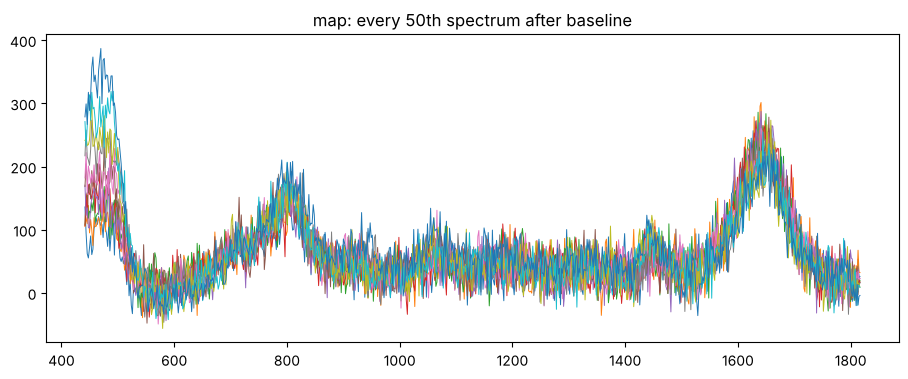

In [5]:
cv_corrected = cv.baseline()
wt = stk.load('../data/wt_raw.mat', verbose=False).trim(441, 1818)
wt_corrected = wt.baseline()
fig, ax = plt.subplots(figsize=(11, 4))
for i in range(0, len(wt), 50):
    ax.plot(wt_corrected.x, wt_corrected.Y[i], lw=0.7)
ax.set_title('map: every 50th spectrum after baseline'); plt.show()